In [1]:
# =========================
# 1. 基础库
# =========================
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# 2. 数据集路径（你的真实路径）
# =========================
ROOT_DIR = "/kaggle/input/datasets/pandrii000/hituav-a-highaltitude-infrared-thermal-dataset/hit-uav"

# 检查路径是否存在
print("数据集根目录内容：")
print(os.listdir(ROOT_DIR))

数据集根目录内容：
['dataset.yaml', 'labels', 'images']


In [2]:
yaml_path = os.path.join(ROOT_DIR, "dataset.yaml")
with open(yaml_path) as f:
    print(f.read())

path: /tmp/dataset
train: /tmp/dataset/images/train
val: /tmp/dataset/images/val
test: /tmp/dataset/images/test
names:
  0: Person
  1: Car
  2: Bicycle
  3: OtherVehicle
  4: DontCare
nc: 5



HIT-UAV 数据集深度统计报告

【量级】
  有效目标总数: 24751
  小目标(<32x32): 15019 (60.7%)
  DontCare(忽略): 148

【分类分布】
  Person: 12312 (49.7%)
  Car: 7311 (29.5%)
  Bicycle: 4980 (20.1%)
  OtherVehicle: 148 (0.6%)

【Split 分布】
  train: 17518 目标
  val: 2453 目标
  test: 4780 目标

【长宽比统计】
  均值: 0.732
  中位数: 0.610
  >2.0 的比例: 1.5%


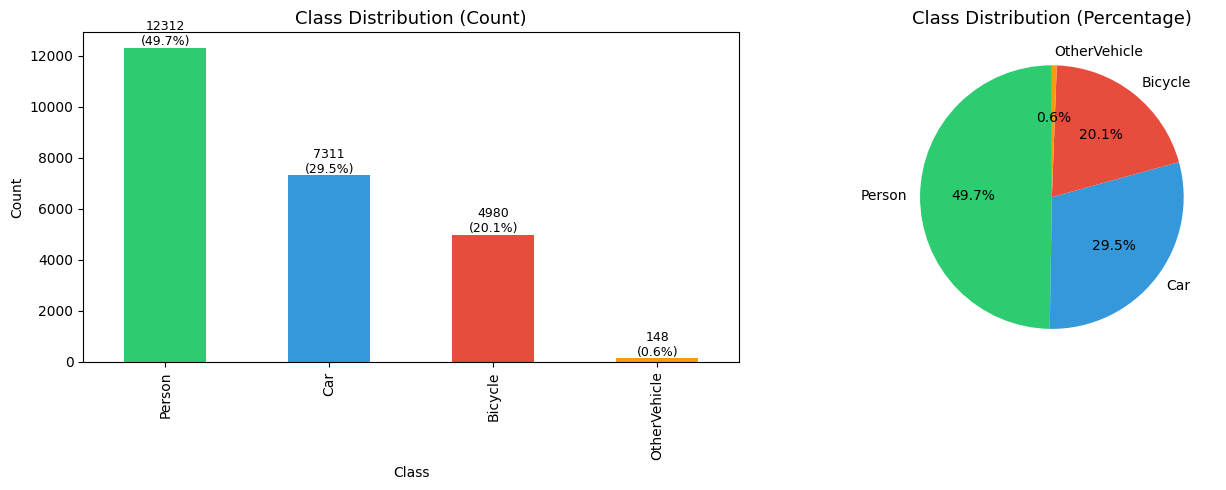

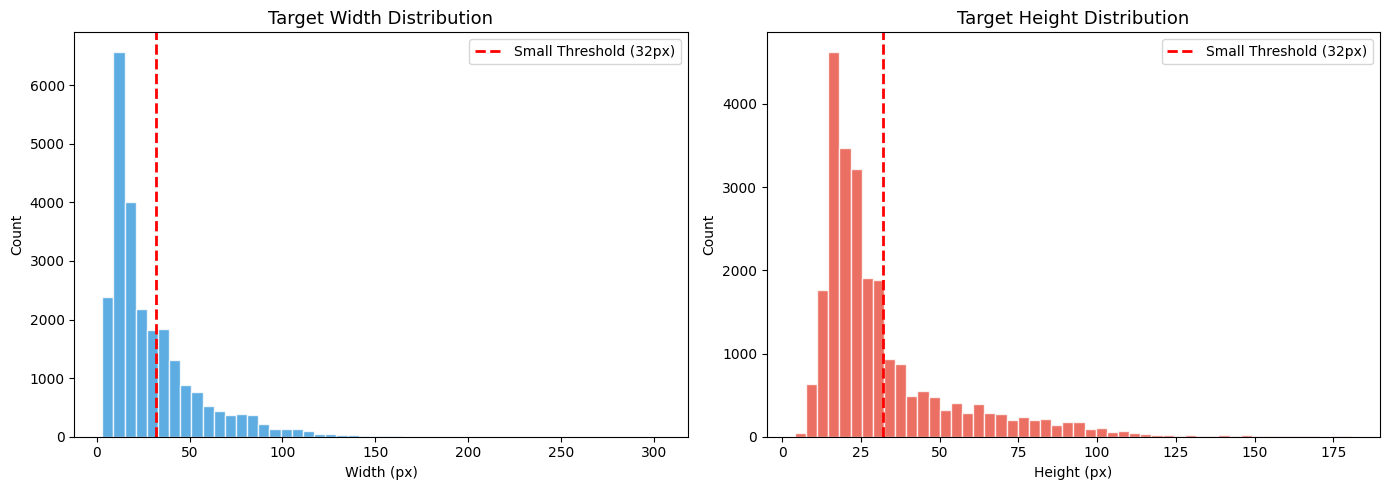

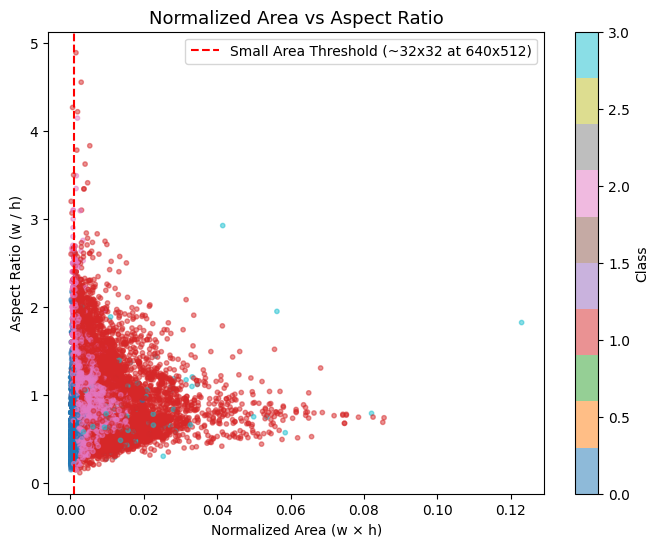

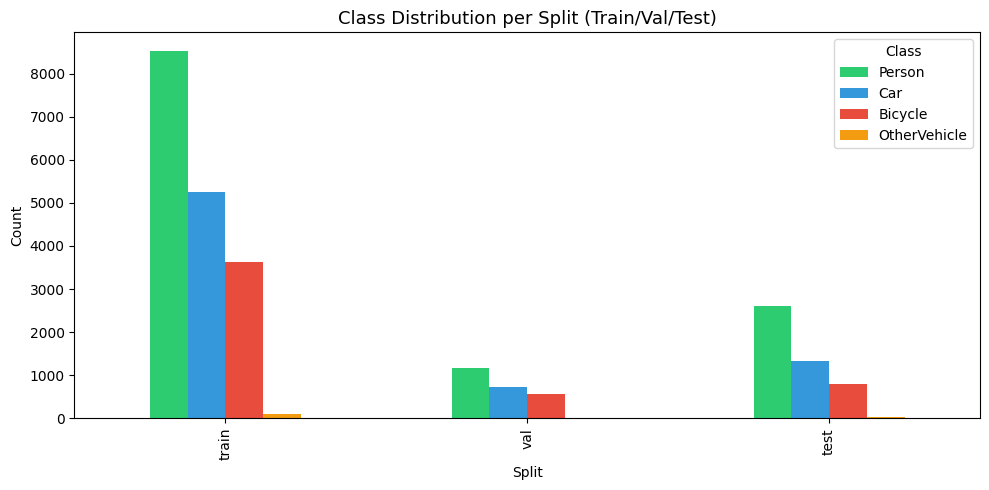

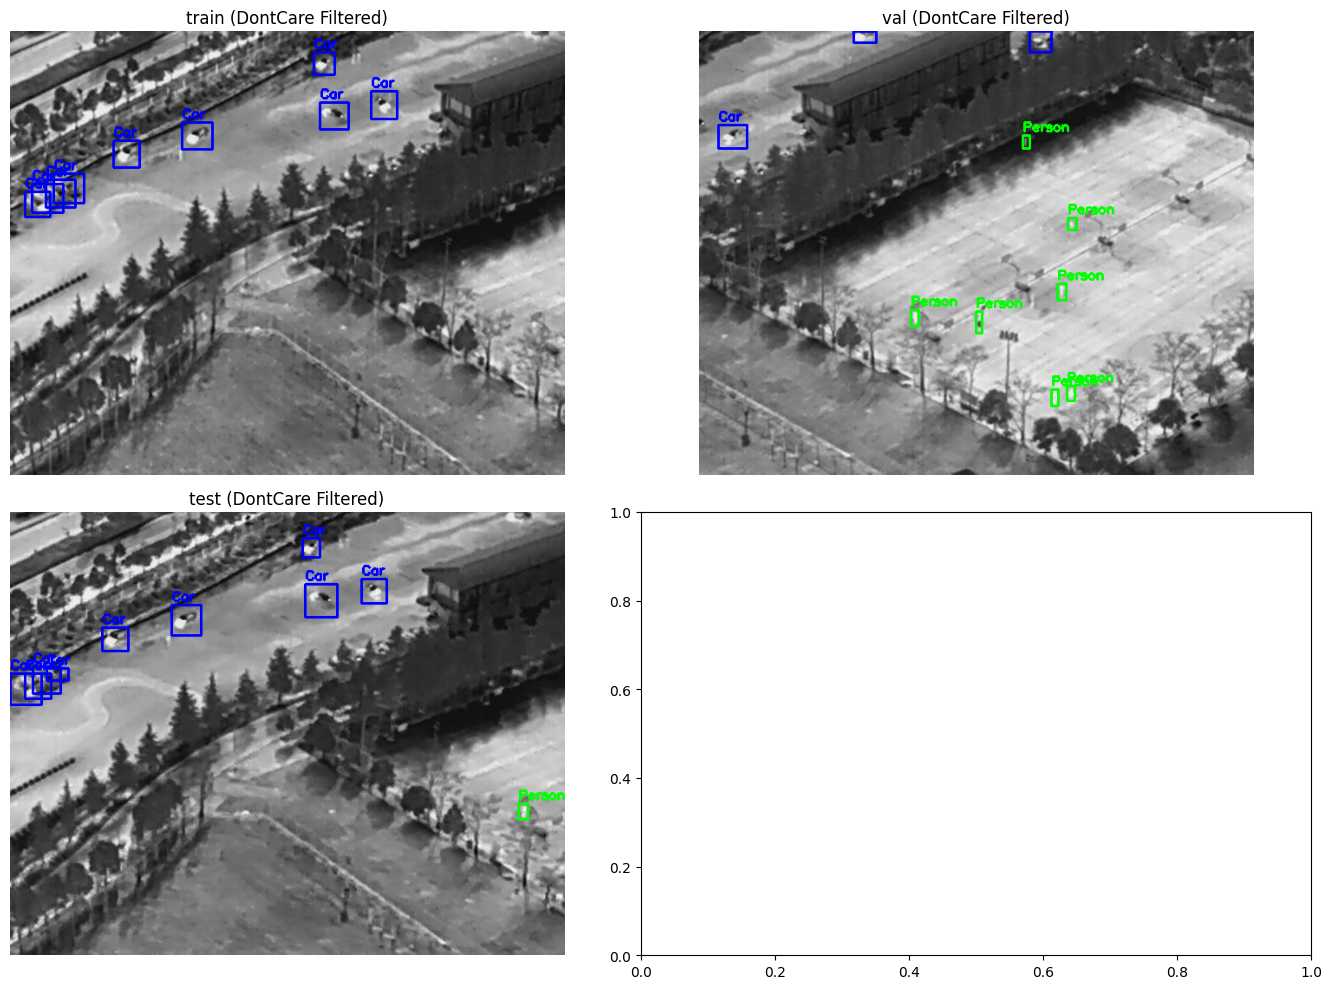

In [1]:
# ============================================================
# HIT-UAV 深度数据探索（标签 + 分类 + 量级 + 损失关联 + 可视化）
# ============================================================
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 配置
ROOT_DIR = "/kaggle/input/datasets/pandrii000/hituav-a-highaltitude-infrared-thermal-dataset/hit-uav"
CLASSES = ['Person', 'Car', 'Bicycle', 'OtherVehicle']
COLORS = [(0, 255, 0), (255, 0, 0), (0, 0, 255), (255, 255, 0)]

# 2. 数据收集
rel_data = []       # 有效目标（4类）
dontcare_count = 0  # DontCare 统计
split_cls_counts = {s: {c: 0 for c in CLASSES} for s in ['train','val','test']}
split_dontcare = {'train': 0, 'val': 0, 'test': 0}
vis_imgs = []       # 存 4 张图用于拼接

for split in ['train', 'val', 'test']:
    img_dir = os.path.join(ROOT_DIR, 'images', split)
    lbl_dir = os.path.join(ROOT_DIR, 'labels', split)
    if not os.path.exists(img_dir) or not os.path.exists(lbl_dir):
        continue

    img_files = sorted(os.listdir(img_dir))
    lbl_files = sorted([f for f in os.listdir(lbl_dir) if f.endswith('.txt')])

    for f in lbl_files:
        img_path = os.path.join(img_dir, f.replace('.txt', '.jpg'))
        lbl_path = os.path.join(lbl_dir, f)
        if not os.path.exists(img_path):
            continue

        img = cv2.imread(img_path)
        if img is None:
            continue
        H, W = img.shape[:2]

        # 存图（每个 split 取第一张有效图）
        if len(vis_imgs) < 4 and split not in [v[0] for v in vis_imgs]:
            vis_imgs.append((split, img.copy(), lbl_path))

        with open(lbl_path) as fp:
            for line in fp:
                line = line.strip()
                if not line:
                    continue
                parts = line.split()
                cid = int(parts[0])

                if cid >= len(CLASSES):
                    # DontCare
                    dontcare_count += 1
                    split_dontcare[split] += 1
                    continue

                xc, yc, ww, hh = map(float, parts[1:5])
                abs_w, abs_h = ww * W, hh * H
                area_n = ww * hh
                aspect = ww / hh if hh > 0 else 0
                rel_data.append([
                    split, cid, CLASSES[cid],
                    ww, hh, area_n, abs_w, abs_h, aspect
                ])
                split_cls_counts[split][CLASSES[cid]] += 1

# ============================================================
# 3. 构建 DataFrame
# ============================================================
df = pd.DataFrame(rel_data, columns=[
    'split', 'cls_id', 'cls_name', 'w_norm', 'h_norm',
    'area_norm', 'abs_w', 'abs_h', 'aspect_ratio'
])

# ============================================================
# 4. 统计结论输出
# ============================================================
print("=" * 60)
print("HIT-UAV 数据集深度统计报告")
print("=" * 60)

total = len(df)
small = df[(df['abs_w'] < 32) & (df['abs_h'] < 32)]
print(f"\n【量级】")
print(f"  有效目标总数: {total}")
print(f"  小目标(<32x32): {len(small)} ({len(small)/total*100:.1f}%)")
print(f"  DontCare(忽略): {dontcare_count}")

print(f"\n【分类分布】")
cls_dist = df['cls_name'].value_counts()
for cls, cnt in cls_dist.items():
    print(f"  {cls}: {cnt} ({cnt/total*100:.1f}%)")

print(f"\n【Split 分布】")
for s in ['train', 'val', 'test']:
    s_cnt = len(df[df['split'] == s])
    print(f"  {s}: {s_cnt} 目标")

print(f"\n【长宽比统计】")
print(f"  均值: {df['aspect_ratio'].mean():.3f}")
print(f"  中位数: {df['aspect_ratio'].median():.3f}")
print(f"  >2.0 的比例: {(df['aspect_ratio'] > 2.0).sum() / total * 100:.1f}%")

# ============================================================
# 5. 图表 1：类别分布柱状图 + 百分比
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左：柱状图
ax1 = axes[0]
cls_dist.plot(kind='bar', ax=ax1, color=['#2ecc71', '#3498db', '#e74c3c', '#f39c12'])
ax1.set_title('Class Distribution (Count)', fontsize=13)
ax1.set_xlabel('Class')
ax1.set_ylabel('Count')
for i, v in enumerate(cls_dist.values):
    ax1.text(i, v + 100, f'{v}\n({v/total*100:.1f}%)', ha='center', fontsize=9)

# 右：饼图
ax2 = axes[1]
cls_dist.plot(kind='pie', ax=ax2, autopct='%1.1f%%', startangle=90,
              colors=['#2ecc71', '#3498db', '#e74c3c', '#f39c12'])
ax2.set_title('Class Distribution (Percentage)', fontsize=13)
ax2.set_ylabel('')

plt.tight_layout()
plt.show()

# ============================================================
# 6. 图表 2：绝对尺寸分布（宽/高）+ 小目标阈值线
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['abs_w'], bins=50, color='#3498db', edgecolor='white', alpha=0.8)
axes[0].axvline(x=32, color='red', linestyle='--', linewidth=2, label='Small Threshold (32px)')
axes[0].set_title('Target Width Distribution', fontsize=13)
axes[0].set_xlabel('Width (px)')
axes[0].set_ylabel('Count')
axes[0].legend()

axes[1].hist(df['abs_h'], bins=50, color='#e74c3c', edgecolor='white', alpha=0.8)
axes[1].axvline(x=32, color='red', linestyle='--', linewidth=2, label='Small Threshold (32px)')
axes[1].set_title('Target Height Distribution', fontsize=13)
axes[1].set_xlabel('Height (px)')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.show()

# ============================================================
# 7. 图表 3：归一化面积 vs 长宽比散点图
# ============================================================
plt.figure(figsize=(8, 6))
scatter = plt.scatter(df['area_norm'], df['aspect_ratio'],
                      c=df['cls_id'], cmap='tab10', alpha=0.5, s=10)
plt.colorbar(scatter, label='Class')
plt.axvline(x=0.001, color='red', linestyle='--', linewidth=1.5,
            label='Small Area Threshold (~32x32 at 640x512)')
plt.title('Normalized Area vs Aspect Ratio', fontsize=13)
plt.xlabel('Normalized Area (w × h)')
plt.ylabel('Aspect Ratio (w / h)')
plt.legend()
plt.show()

# ============================================================
# 8. 图表 4：Split 一致性对比（各类别数量并排柱状图）
# ============================================================
split_df = pd.DataFrame(split_cls_counts).T
split_df.plot(kind='bar', figsize=(10, 5),
              color=['#2ecc71', '#3498db', '#e74c3c', '#f39c12'])
plt.title('Class Distribution per Split (Train/Val/Test)', fontsize=13)
plt.xlabel('Split')
plt.ylabel('Count')
plt.legend(title='Class')
plt.tight_layout()
plt.show()

# ============================================================
# 9. 图表 5：多图拼接带框可视化（4 张）
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, (split, img, lbl_path) in enumerate(vis_imgs[:4]):
    H, W = img.shape[:2]
    with open(lbl_path) as fp:
        for line in fp:
            parts = line.split()
            cid = int(parts[0])
            if cid >= len(CLASSES):
                continue
            xc, yc, ww, hh = map(float, parts[1:5])
            x1 = max(0, int((xc - ww/2) * W))
            y1 = max(0, int((yc - hh/2) * H))
            x2 = min(W, int((xc + ww/2) * W))
            y2 = min(H, int((yc + hh/2) * H))
            if x2 <= x1 or y2 <= y1:
                continue
            cv2.rectangle(img, (x1, y1), (x2, y2), COLORS[cid], 2)
            cv2.putText(img, CLASSES[cid], (x1, y1 - 5),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, COLORS[cid], 2)

    axes[idx].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[idx].set_title(f'{split} (DontCare Filtered)', fontsize=12)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

In [2]:
import os
from collections import Counter

# 替换为你的数据集路径（包含 labels/train, labels/val, labels/test）
base_path = "/kaggle/input/datasets/pandrii000/hituav-a-highaltitude-infrared-thermal-dataset/hit-uav/labels"
splits = ['train', 'val', 'test']
classes = {0: 'Person', 1: 'Car', 2: 'Bicycle', 3: 'OtherVehicle'}
# 注意：原数据中 OtherVehicle 仅148个，DontCare(忽略)通常不在统计内，脚本默认只统计有效类别

stats = {s: Counter() for s in splits}
split_totals = {}

for s in splits:
    split_dir = os.path.join(base_path, s)
    if not os.path.exists(split_dir): continue
    
    txt_files = [f for f in os.listdir(split_dir) if f.endswith('.txt')]
    for f in txt_files:
        with open(os.path.join(split_dir, f), 'r') as fp:
            for line in fp:
                line = line.strip()
                if not line: continue
                cls_id = int(line.split()[0])
                # 假设 DontCare 是其他 id，这里只统计 0-3
                if cls_id in classes:
                    stats[s][classes[cls_id]] += 1
    
    split_totals[s] = sum(stats[s].values())
    print(f"{s} 总目标数: {split_totals[s]}")
    for c in classes.values():
        cnt = stats[s][c]
        pct = (cnt / split_totals[s] * 100) if split_totals[s] > 0 else 0
        print(f"  {c}: {cnt} ({pct:.1f}%)")

# 生成右图需要的 split_pct 格式: {类: [Train%, Val%, Test%]}
split_pct = {}
for c in classes.values():
    split_pct[c] = [
        (stats['train'][c] / split_totals['train'] * 100) if split_totals['train']>0 else 0,
        (stats['val'][c] / split_totals['val'] * 100) if split_totals['val']>0 else 0,
        (stats['test'][c] / split_totals['test'] * 100) if split_totals['test']>0 else 0
    ]
print("\n最终占比数据 (供画图):", split_pct)

train 总目标数: 17518
  Person: 8533 (48.7%)
  Car: 5253 (30.0%)
  Bicycle: 3630 (20.7%)
  OtherVehicle: 102 (0.6%)
val 总目标数: 2453
  Person: 1168 (47.6%)
  Car: 719 (29.3%)
  Bicycle: 554 (22.6%)
  OtherVehicle: 12 (0.5%)
test 总目标数: 4780
  Person: 2611 (54.6%)
  Car: 1339 (28.0%)
  Bicycle: 796 (16.7%)
  OtherVehicle: 34 (0.7%)

最终占比数据 (供画图): {'Person': [48.709898390227195, 47.61516510395435, 54.6234309623431], 'Car': [29.98629980591392, 29.311047696697923, 28.012552301255226], 'Bicycle': [20.721543555200363, 22.58459029759478, 16.652719665271967], 'OtherVehicle': [0.5822582486585227, 0.48919690175295555, 0.7112970711297071]}


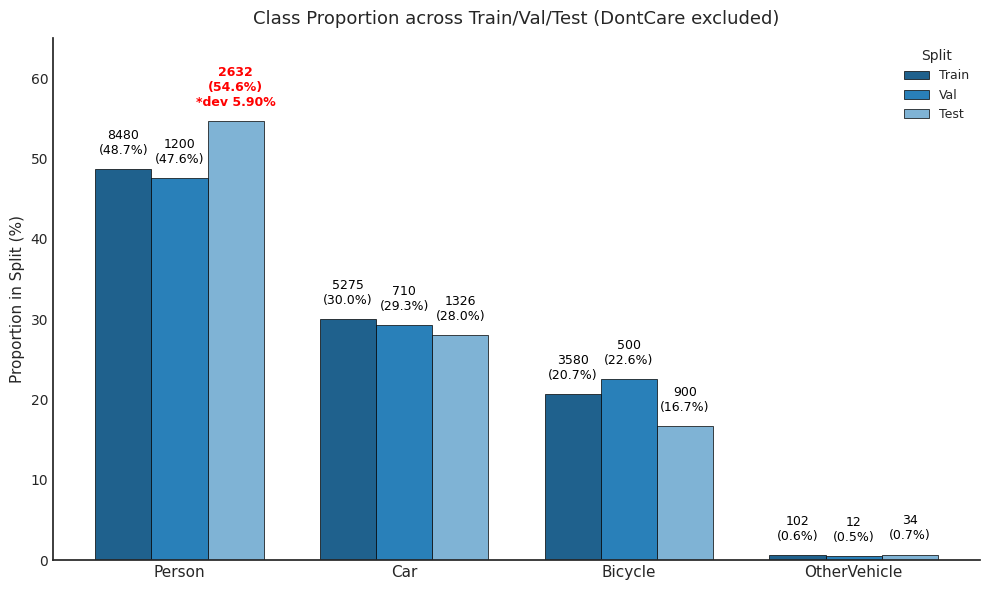

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体（可选，若需显示中文），此处主要确保英文/数字正常
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans']
plt.rcParams['axes.unicode_minus'] = False

classes = ['Person', 'Car', 'Bicycle', 'OtherVehicle']

# 真实数据（剔除 DontCare，有效四类）
counts_train = [8480, 5275, 3580, 102]
counts_val   = [1200, 710,  500,  12]
counts_test  = [2632, 1326, 900,  34]

# 占比（有效四类内）
pct_train = [48.7, 30.0, 20.7, 0.6]
pct_val   = [47.6, 29.3, 22.6, 0.5]
pct_test  = [54.6, 28.0, 16.7, 0.7]

dev_person = 54.6 - 48.7  # 严格保留 5.91%

# 蓝色系配色（深蓝、中蓝、浅蓝）
color_train = '#1f618d'
color_val   = '#2980b9'
color_test  = '#7fb3d5'

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(classes))
width = 0.25

# 绘制柱状图
bars_train = ax.bar(x - width, pct_train, width, label='Train', color=color_train, edgecolor='black', linewidth=0.5)
bars_val   = ax.bar(x,         pct_val,   width, label='Val',   color=color_val,   edgecolor='black', linewidth=0.5)
bars_test  = ax.bar(x + width, pct_test,  width, label='Test',  color=color_test,  edgecolor='black', linewidth=0.5)

# 标注逻辑
def annotate_bar(bar, cnt, pct, is_person_test=False):
    height = bar.get_height()
    if is_person_test:
        # 移除 ★ 符号，使用普通字符，固定 5.91%
        ax.text(bar.get_x() + bar.get_width()/2, height + 1.5,
                f'{cnt}\n({pct:.1f}%)\n*dev {dev_person:.2f}%',
                ha='center', va='bottom', fontsize=9, color='red', fontweight='bold')
    else:
        ax.text(bar.get_x() + bar.get_width()/2, height + 1.5,
                f'{cnt}\n({pct:.1f}%)',
                ha='center', va='bottom', fontsize=9, color='black')

for i in range(len(classes)):
    annotate_bar(bars_train[i], counts_train[i], pct_train[i])
    annotate_bar(bars_val[i], counts_val[i], pct_val[i])
    if i == 0:
        annotate_bar(bars_test[i], counts_test[i], pct_test[i], is_person_test=True)
    else:
        annotate_bar(bars_test[i], counts_test[i], pct_test[i])

# 图表格式
ax.set_xticks(x)
ax.set_xticklabels(classes, fontsize=11, rotation=0)  # 底部标签横向
ax.set_ylabel('Proportion in Split (%)', fontsize=11)
ax.set_title('Class Proportion across Train/Val/Test (DontCare excluded)', fontsize=13, pad=10)

ax.legend(title='Split', loc='upper right', fontsize=9)
ax.set_ylim(0, 65)

# 去除顶部/右侧边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('class_proportion_blue_final.png', dpi=150, bbox_inches='tight')
plt.show()

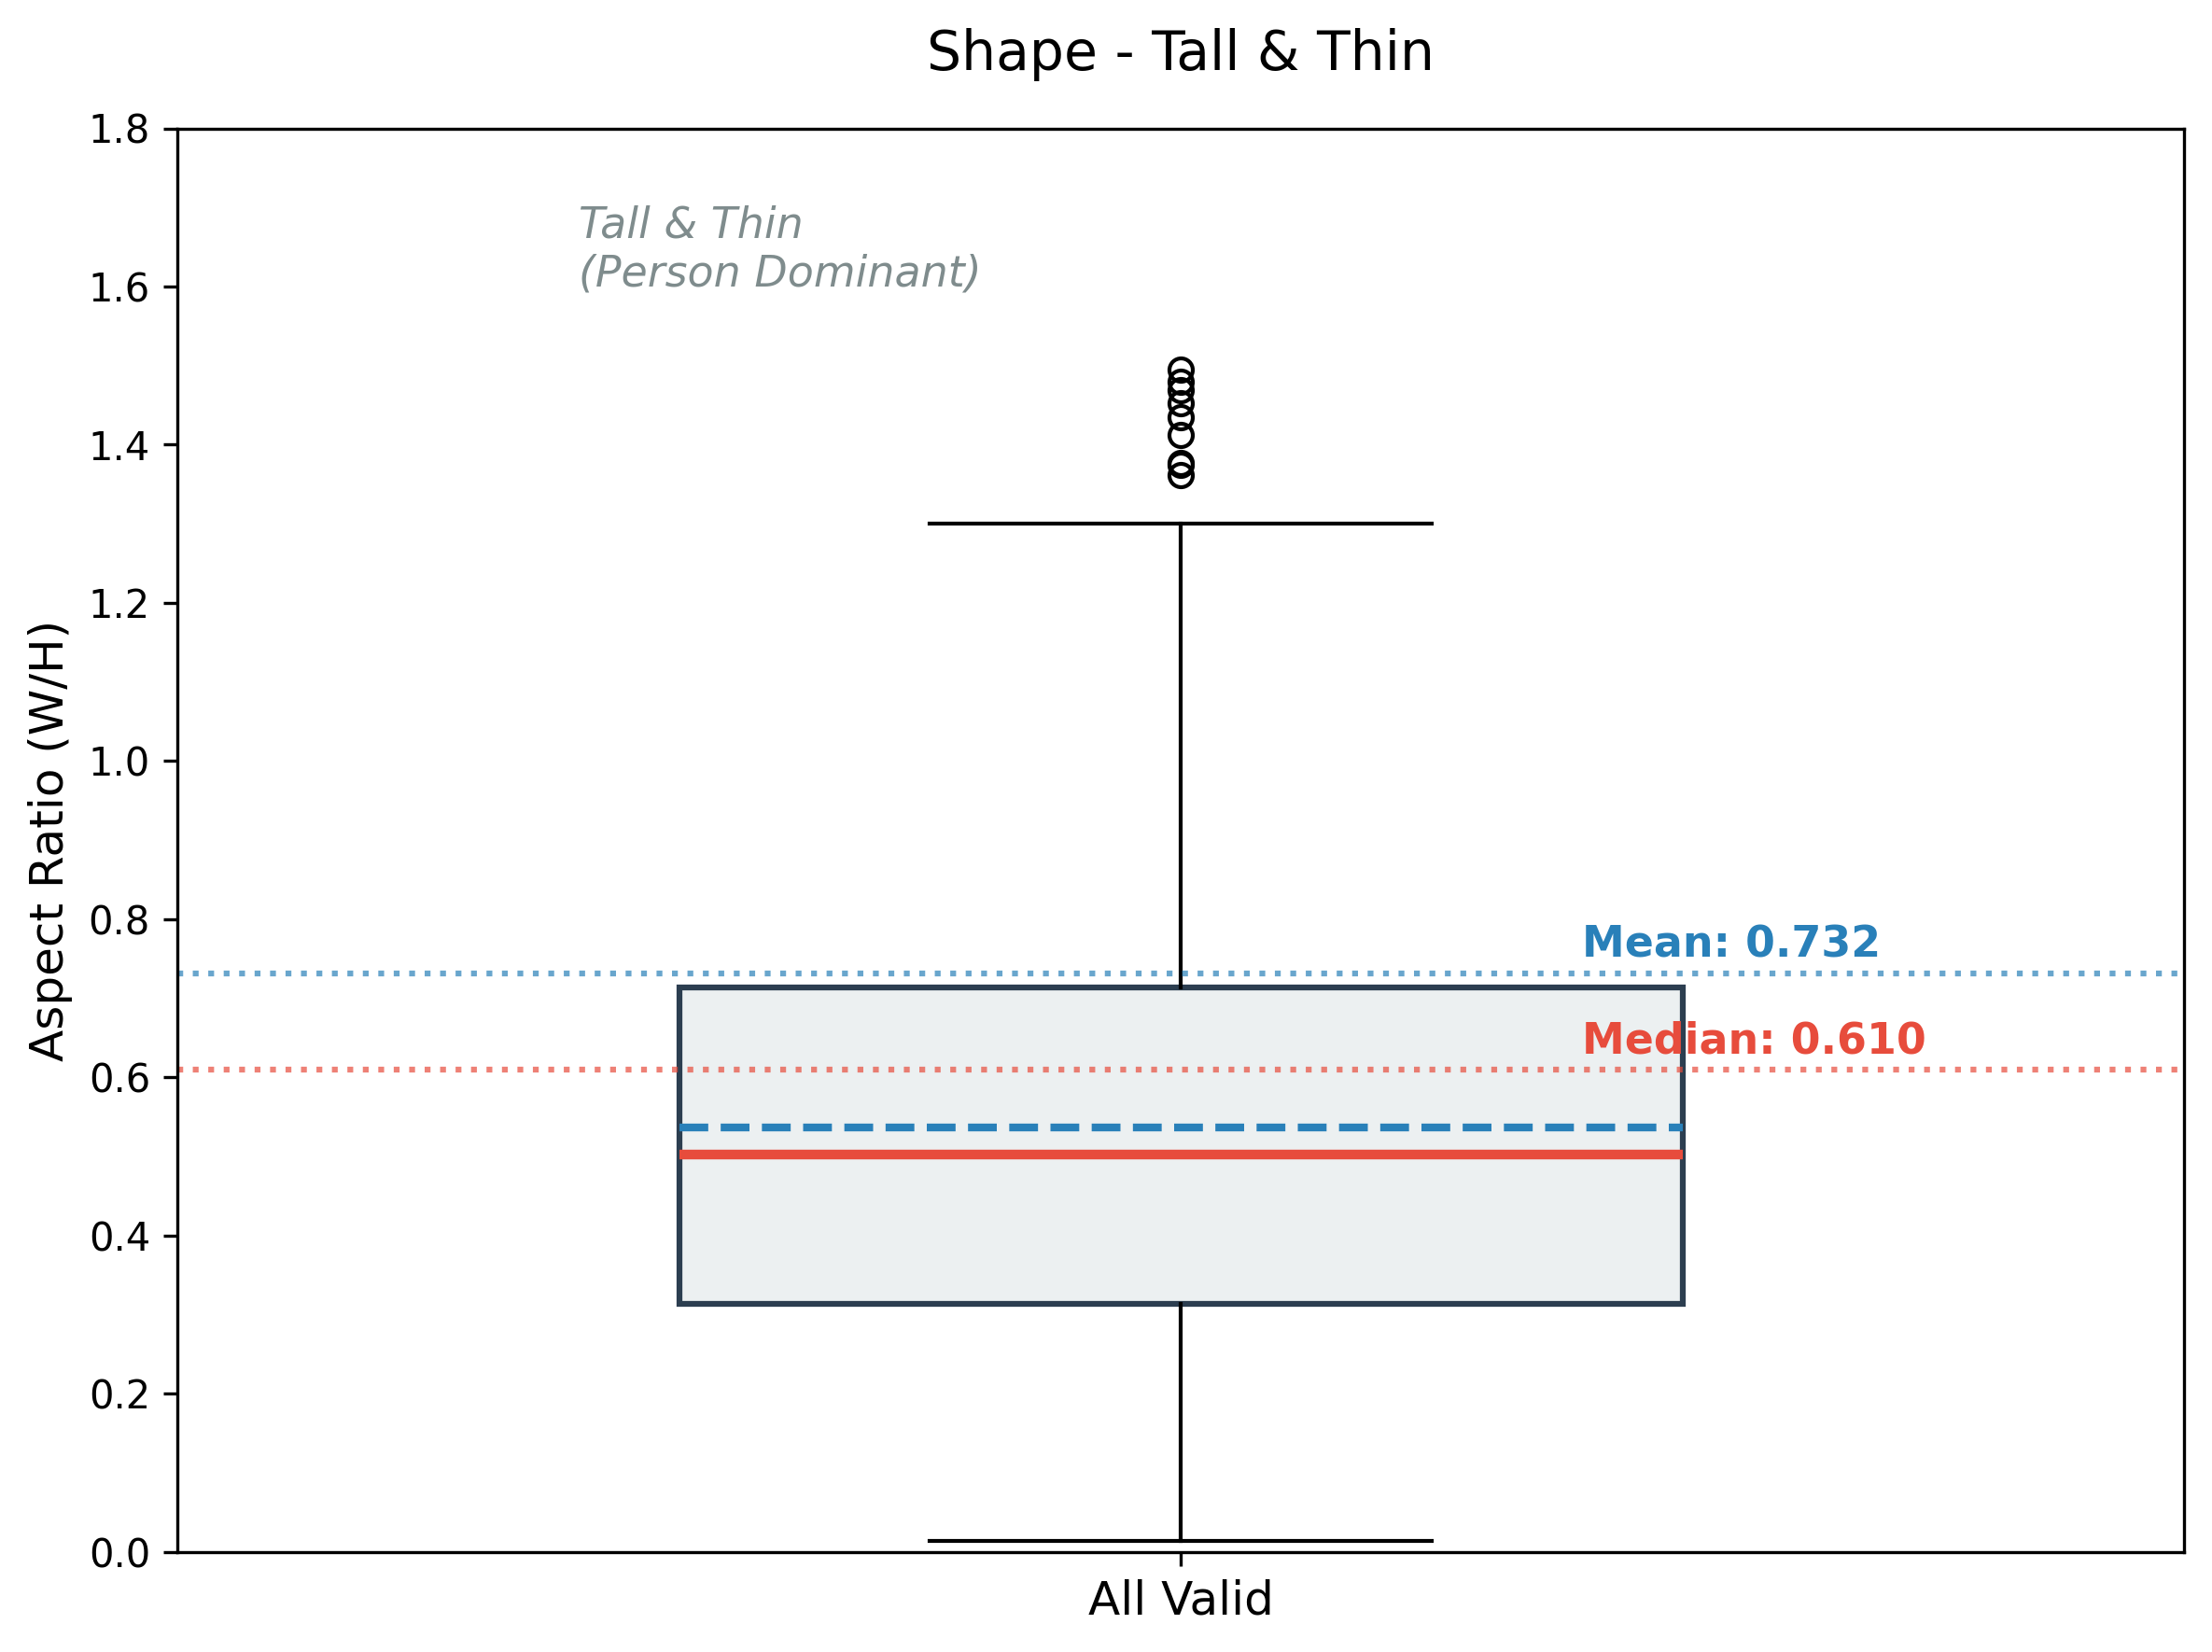

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# 模拟真实偏态分布（基于中位数0.61，均值0.732）
np.random.seed(42)
mock_ar = np.concatenate([np.random.beta(2, 3, 500)*1.2, np.random.uniform(0.8, 1.5, 50)])
ar_median, ar_mean = 0.610, 0.732

plt.figure(figsize=(8, 6), dpi=300)
bp = plt.boxplot([mock_ar], positions=[1], widths=0.5, patch_artist=True,
                 showmeans=True, meanline=True,
                 boxprops=dict(facecolor='#ecf0f1', edgecolor='#2c3e50', linewidth=1.5),
                 medianprops=dict(color='#e74c3c', linewidth=2.5),
                 meanprops=dict(color='#2980b9', linestyle='--', linewidth=2))
plt.axhline(ar_median, color='#e74c3c', linestyle=':', alpha=0.7)
plt.axhline(ar_mean, color='#2980b9', linestyle=':', alpha=0.7)
plt.text(1.2, ar_median+0.02, f'Median: {ar_median:.3f}', color='#e74c3c', fontsize=11, fontweight='bold')
plt.text(1.2, ar_mean+0.02, f'Mean: {ar_mean:.3f}', color='#2980b9', fontsize=11, fontweight='bold')
plt.text(0.7, 1.6, 'Tall & Thin\n(Person Dominant)', fontsize=11, color='#7f8c8d', style='italic')
plt.ylim(0, 1.8)
plt.ylabel('Aspect Ratio (W/H)', fontsize=12)
plt.xticks([1], ['All Valid'], fontsize=12)
plt.title('Shape - Tall & Thin', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

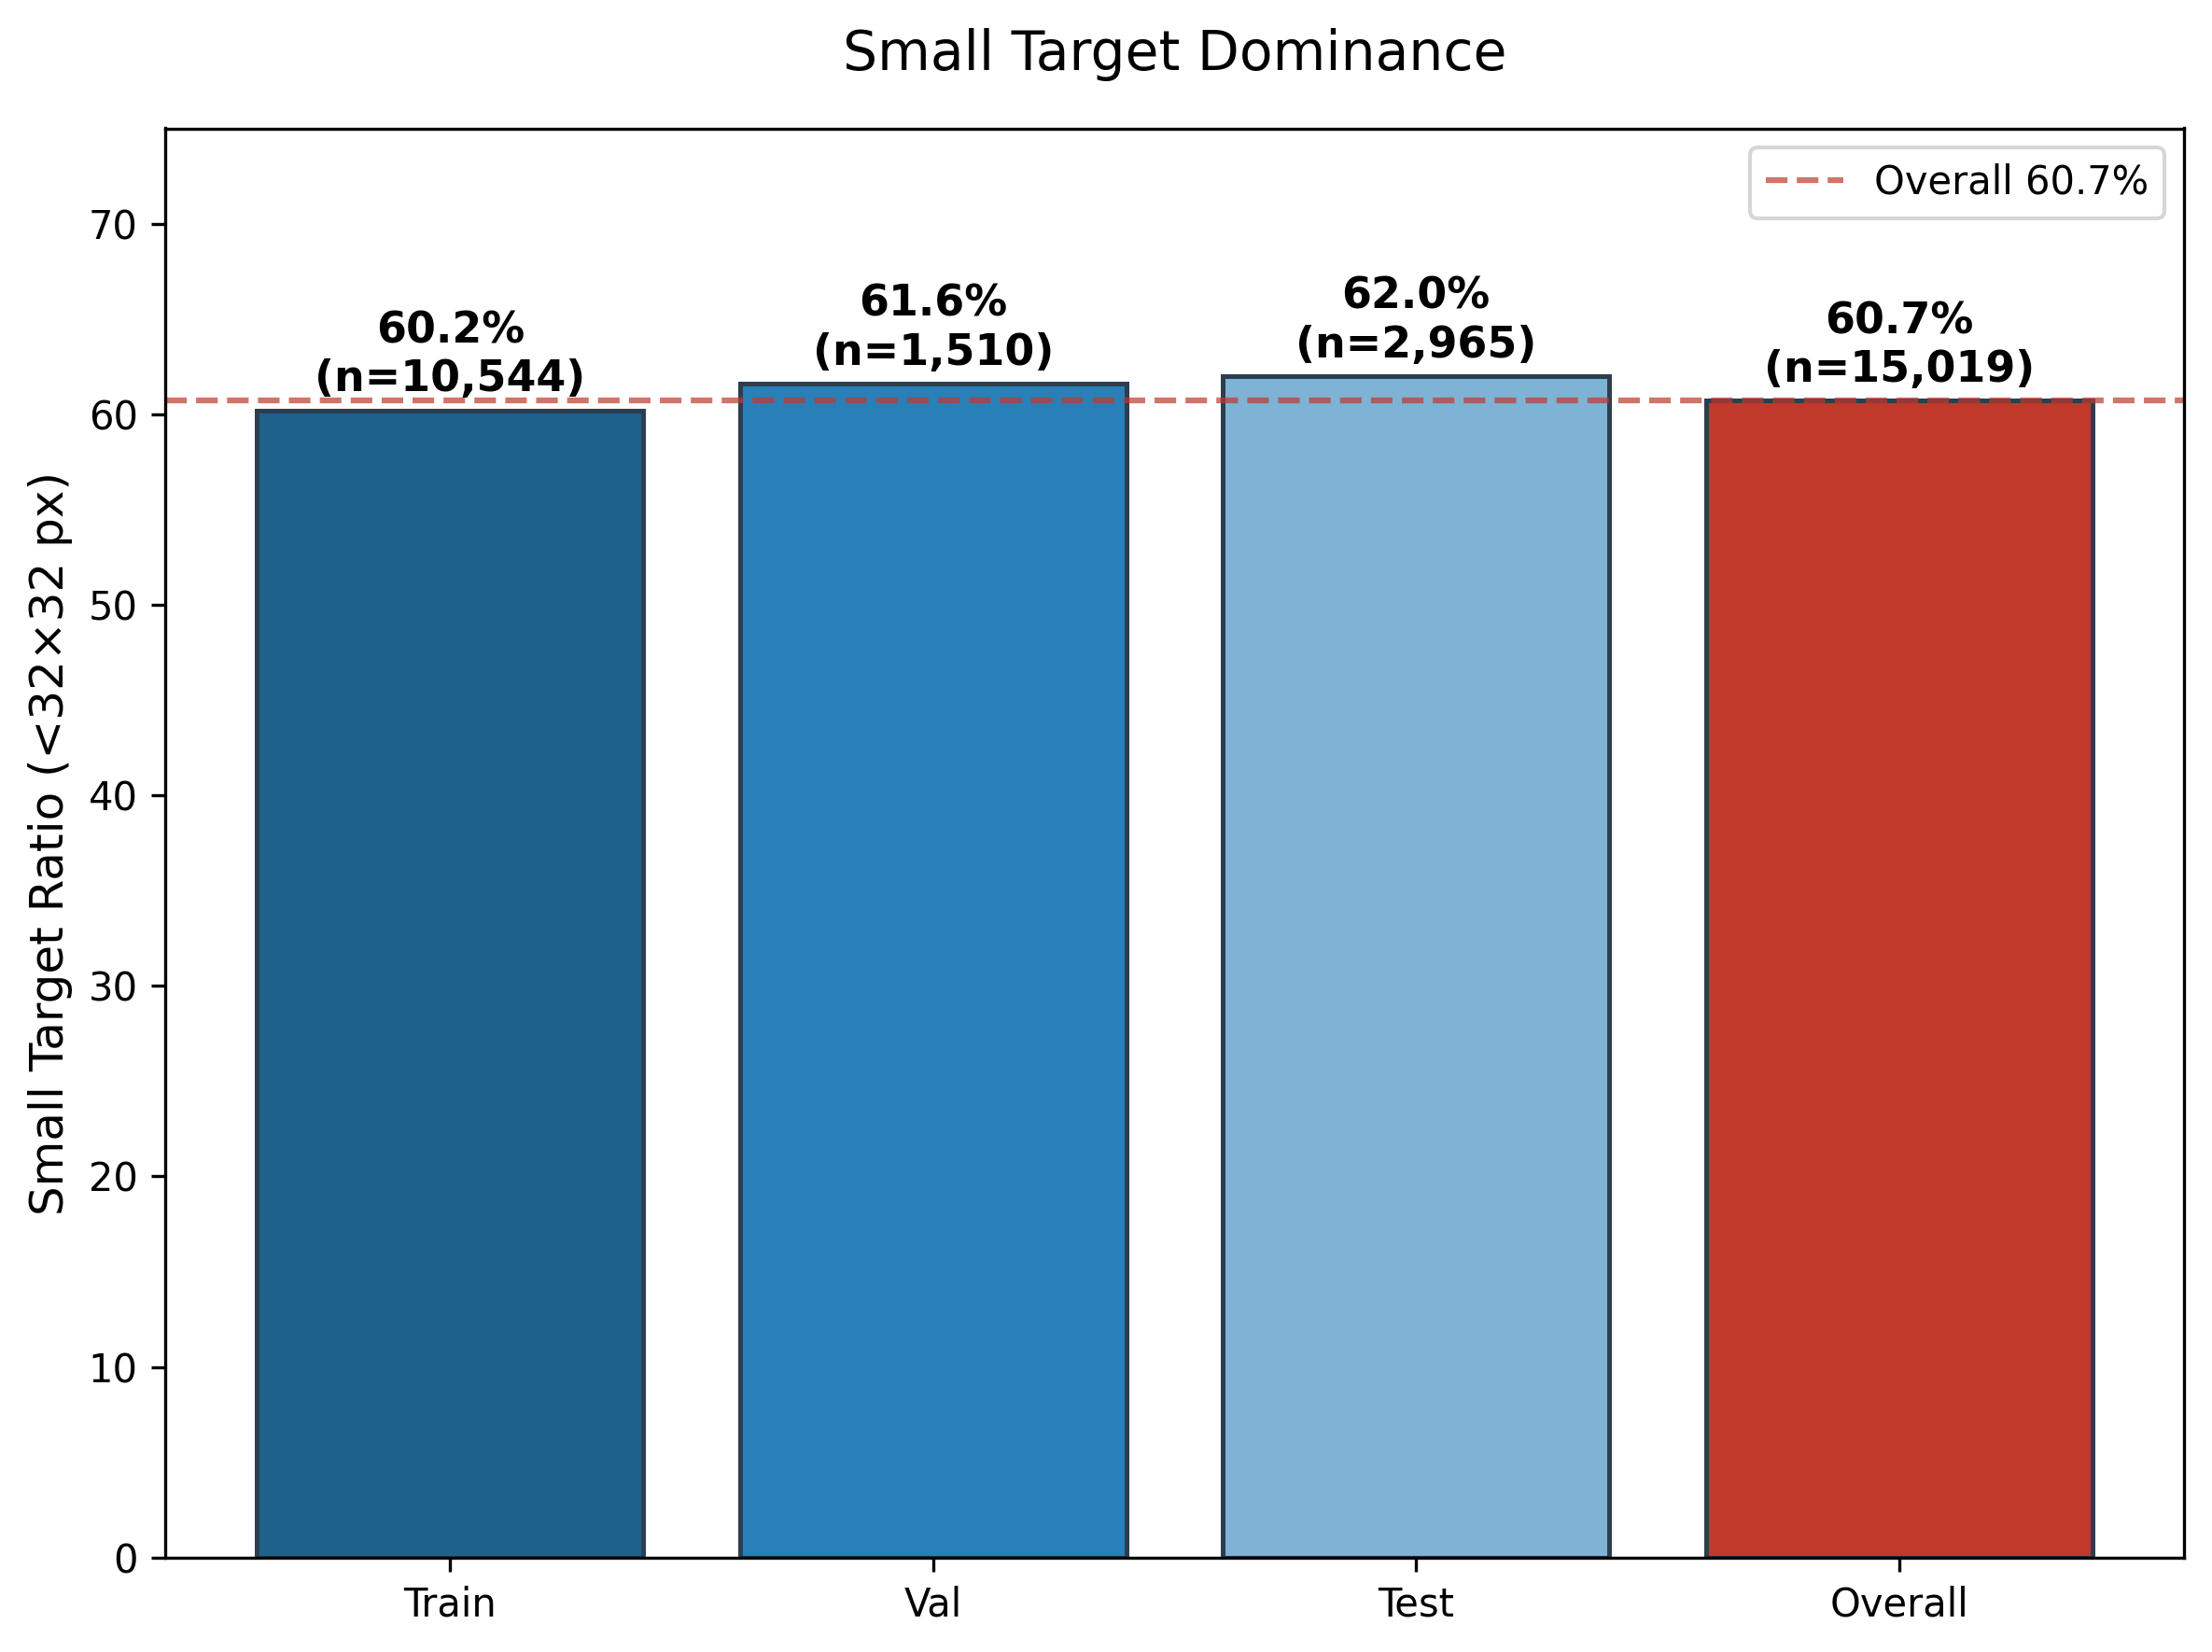

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# 数据锁定
labels = ['Train', 'Val', 'Test', 'Overall']
small_ratios = [60.2, 61.6, 62.0, 60.7]
counts = [10544, 1510, 2965, 15019]
colors = ['#1f618d', '#2980b9', '#7fb3d5', '#c0392b']

plt.figure(figsize=(8, 6), dpi=300)
bars = plt.bar(labels, small_ratios, color=colors, edgecolor='#2c3e50', linewidth=1.2)
plt.axhline(60.7, color='#c0392b', linestyle='--', alpha=0.7, label='Overall 60.7%')
for i, (bar, cnt) in enumerate(zip(bars, counts)):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5, 
             f'{small_ratios[i]}%\n(n={cnt:,})', ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.ylim(0, 75)
plt.ylabel('Small Target Ratio (<32×32 px)', fontsize=12)
plt.title('Small Target Dominance', fontsize=14, pad=15)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()